In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
from matplotlib import pyplot as plt
import netCDF4
import xarray as xr

In [2]:
#读取数据
ds = xr.open_dataset('200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc')
print(ds)
#查看属性以便后续筛选
print(ds["xch4"].attrs)
print(ds["xch4"].encoding)

<xarray.Dataset> Size: 54MB
Dimensions:                  (time: 210, bnds: 2, lat: 36, lon: 72, pressure: 10)
Coordinates:
  * time                     (time) datetime64[ns] 2kB 2003-01-16T12:00:00 .....
  * lat                      (lat) float64 288B -87.5 -82.5 -77.5 ... 82.5 87.5
  * lon                      (lon) float64 576B -177.5 -172.5 ... 172.5 177.5
Dimensions without coordinates: bnds, pressure
Data variables:
    time_bnds                (time, bnds) datetime64[ns] 3kB ...
    lat_bnds                 (lat, bnds) float64 576B ...
    lon_bnds                 (lon, bnds) float64 1kB ...
    pre                      (pressure) float64 80B ...
    pre_bnds                 (pressure, bnds) float64 160B ...
    land_fraction            (lat, lon) float64 21kB ...
    xch4                     (time, lat, lon) float32 2MB ...
    xch4_nobs                (time, lat, lon) float64 4MB ...
    xch4_stderr              (time, lat, lon) float32 2MB ...
    xch4_stddev              (tim

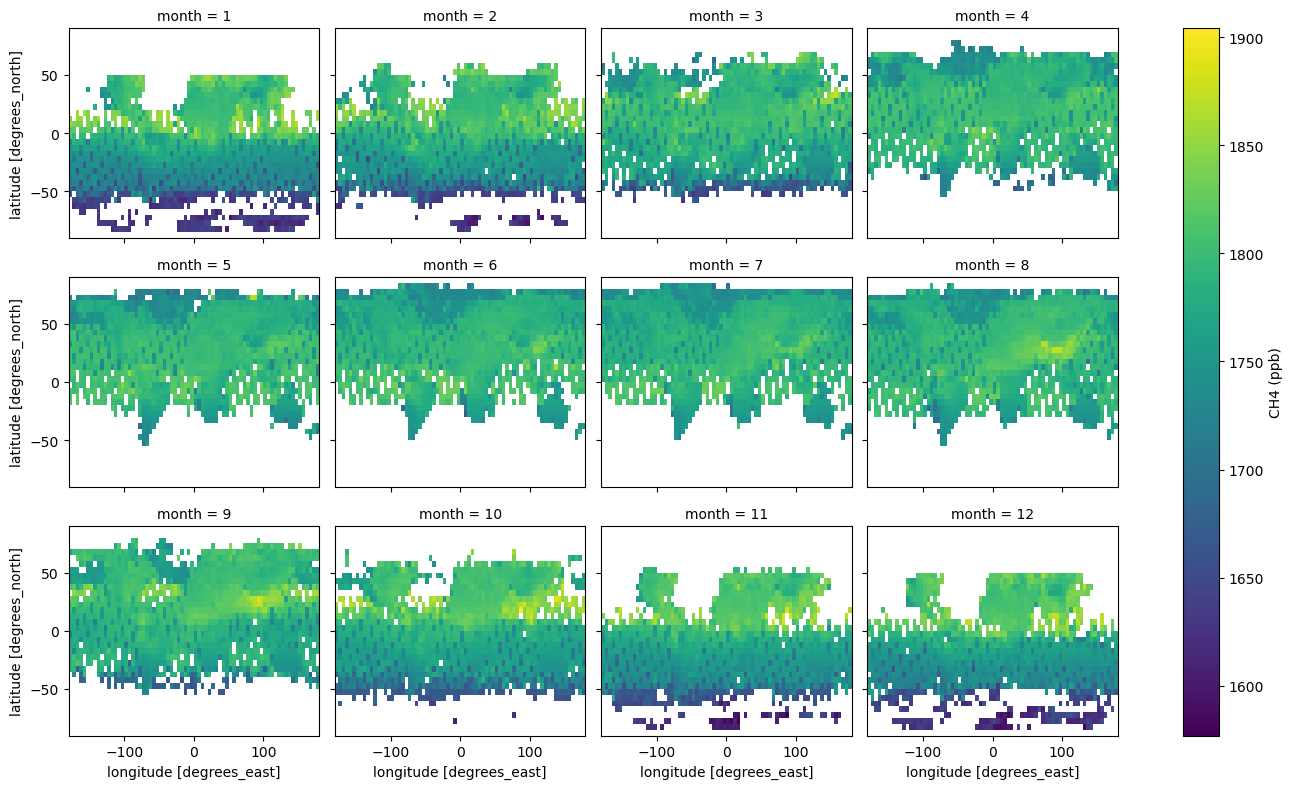

In [3]:
# 根据数据属性读取缺失值并筛除
fill_value = np.float32(ds["xch4"].attrs["fill_value"])
ch4 = ds["xch4"].where(ds["xch4"] != fill_value)

# 将单位转换为 ppb
ch4 = ch4 * 1e9

# 按月份计算气候态，忽略 NaN
monthly_ch4 = ch4.groupby("time.month").mean("time", skipna=True)

# 绘制12幅图，每行4幅
monthly_ch4.plot(
    x="lon",
    y="lat",
    col="month",
    col_wrap=4,
    cmap="viridis",
    figsize=(14, 8),
    cbar_kwargs={"label": "CH4 (ppb)"}
)

plt.show()

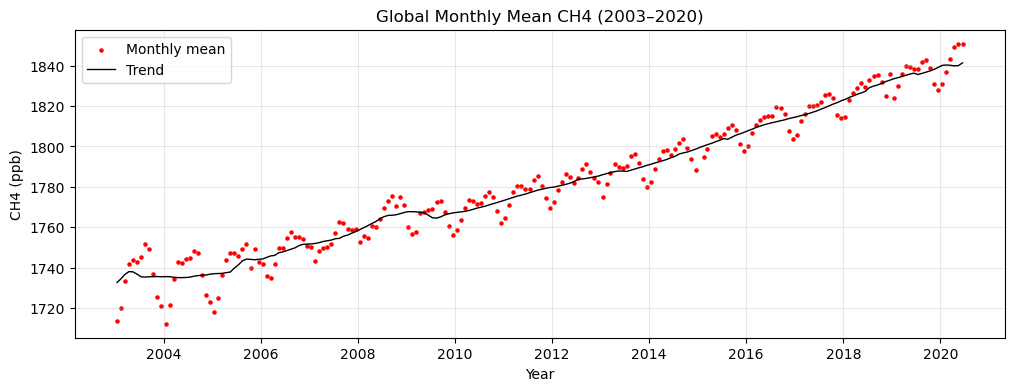

In [8]:
# 设置时间范围
ch4_period = ch4.sel(time=slice("2003-01", "2020-06"))

# 根据纬度余弦计算面积权重
weights = np.cos(np.deg2rad(ch4_period["lat"]))

# 对每个月的所有经纬度网格求面积加权平均
global_ch4 = ch4_period.weighted(weights).mean(dim=["lat", "lon"], skipna=True)

# 计算趋势，使用min_periods使趋势线从头到尾不间断
trend = global_ch4.rolling(time=12, center=True, min_periods=1).mean()
plt.figure(figsize=(12, 4))

# 绘图，加入月均浓度散点和趋势线
plt.scatter(global_ch4["time"], global_ch4,color="red", s=5, label="Monthly mean")
plt.plot(trend["time"], trend,color="black", linewidth=1, label="Trend")
plt.title("Global Monthly Mean CH4 (2003–2020)")
plt.xlabel("Year")
plt.ylabel("CH4 (ppb)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

纬度： -12.5 经度： -147.5


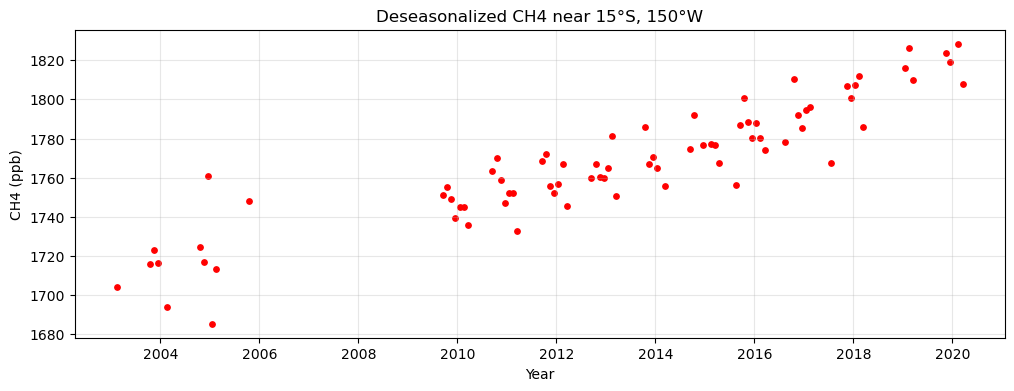

In [9]:
# 选择距离南纬15度、西经150度最近的网格
point = ch4.sel(lat=-15, lon=-150, method="nearest")
point = point.sel(time=slice("2003-01", "2020-06"))

# 打印实际选中的网格中心
print("纬度：", float(point["lat"]), "经度：", float(point["lon"]))

# 计算该位置的逐月气候态
monthly_mean = point.groupby("time.month").mean("time", skipna=True)

# 去除季节变化，再加回整个时段的平均浓度
deseasonalized = point.groupby("time.month") - monthly_mean + point.mean("time")

#绘图
plt.figure(figsize=(12, 4))
plt.scatter(deseasonalized["time"], deseasonalized,
            color="red", s=15)
plt.title("Deseasonalized CH4 near 15°S, 150°W")
plt.xlabel("Year")
plt.ylabel("CH4 (ppb)")
plt.grid(alpha=0.3)
plt.show()

In [10]:
# 读取海温数据
ds_sst = xr.open_dataset("NOAA_NCDC_ERSST_v3b_SST.nc")

# 查看数据属性
# print(ds_sst)
# print(ds_sst.attrs)

# 选择目标区域并排除缺失值标记，计算均值时排除
sst = ds_sst["sst"].sel(lat=slice(-5, 5), lon=slice(190, 240))
sst = sst.where(sst != -999)

# 计算每年每个月尼诺3.4区域的面积加权平均海温
weights = np.cos(np.deg2rad(sst["lat"]))
sst_mean = sst.weighted(weights).mean(["lat", "lon"], skipna=True)

# 计算1960—2016年各月份的多年平均海温
sst_climatology = sst_mean.groupby("time.month").mean("time", skipna=True)

# 每个月的海温减去对应月份的气候态
sst_anomalies = sst_mean.groupby("time.month") - sst_climatology

# 查看12个月的气候态
print(sst_climatology)

<xarray.DataArray 'sst' (month: 12)> Size: 96B
array([26.56778908, 26.74227524, 27.23960686, 27.69374657, 27.79521561,
       27.59774971, 27.1989212 , 26.8242054 , 26.73782921, 26.71714211,
       26.69328499, 26.6130867 ])
Coordinates:
  * month    (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
Attributes:
    pointwidth:          1.0
    valid_min:           -3.0
    valid_max:           45.0
    units:               degree_Celsius
    long_name:           Extended reconstructed sea surface temperature
    standard_name:       sea_surface_temperature
    iridl:hasSemantics:  iridl:SeaSurfaceTemperature


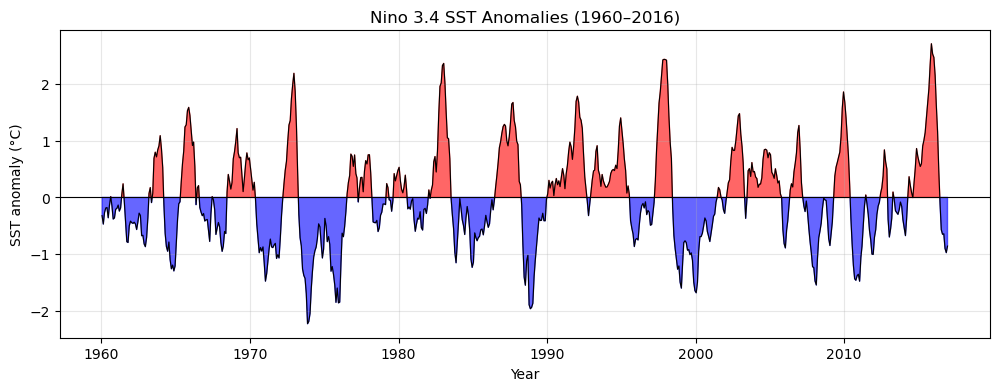

In [11]:
plt.figure(figsize=(12, 4))

# 绘制海温异常折线和零线
plt.plot(sst_anomalies["time"], sst_anomalies, color="black", linewidth=0.8)
plt.axhline(0, color="black", linewidth=0.8)

# 正异常与零线之间填充红色
plt.fill_between(
    sst_anomalies["time"], sst_anomalies, 0,
    where=(sst_anomalies >= 0),
    color="red", alpha=0.6, interpolate=True
)

# 负异常与零线之间填充蓝色
plt.fill_between(
    sst_anomalies["time"], sst_anomalies, 0,
    where=(sst_anomalies < 0),
    color="blue", alpha=0.6, interpolate=True
)

plt.xlabel("Year")
plt.ylabel("SST anomaly (°C)")
plt.title("Nino 3.4 SST Anomalies (1960–2016)")
plt.grid(alpha=0.3)
plt.show()

In [12]:
#先打印数据的属性等信息查阅
# 跳过报错的时间边界变量
ds_rain = xr.open_dataset(
    "precip.mon.mean.nc",
    drop_variables="time_bnds"
)

# 查看数据基本信息
print(ds_rain)
print("\n降水属性：", ds_rain["precip"].attrs)
print("\n降水编码：", ds_rain["precip"].encoding)

<xarray.Dataset> Size: 24MB
Dimensions:   (lat: 72, nv: 2, lon: 144, time: 570)
Coordinates:
  * lat       (lat) float32 288B -88.75 -86.25 -83.75 ... 83.75 86.25 88.75
  * lon       (lon) float32 576B 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
  * time      (time) datetime64[ns] 5kB 1979-01-01 1979-02-01 ... 2026-06-01
Dimensions without coordinates: nv
Data variables:
    lat_bnds  (lat, nv) float32 576B ...
    lon_bnds  (lon, nv) float32 1kB ...
    precip    (time, lat, lon) float32 24MB ...
Attributes: (12/18)
    Conventions:           CF-1.0
    curator:               Dr. Jian-Jian Wang\nESSIC, University of Maryland ...
    citation:              Adler, R.F., G.J. Huffman, A. Chang, R. Ferraro, P...
    title:                 GPCP Version 2.3 Combined Precipitation Dataset (F...
    platform:              NOAA POES (Polar Orbiting Environmental Satellites)
    source_obs:            CDR RSS SSMI/SSMIS Tbs over ocean \nCDR SSMI/SSMIS...
    ...                    ...
    s

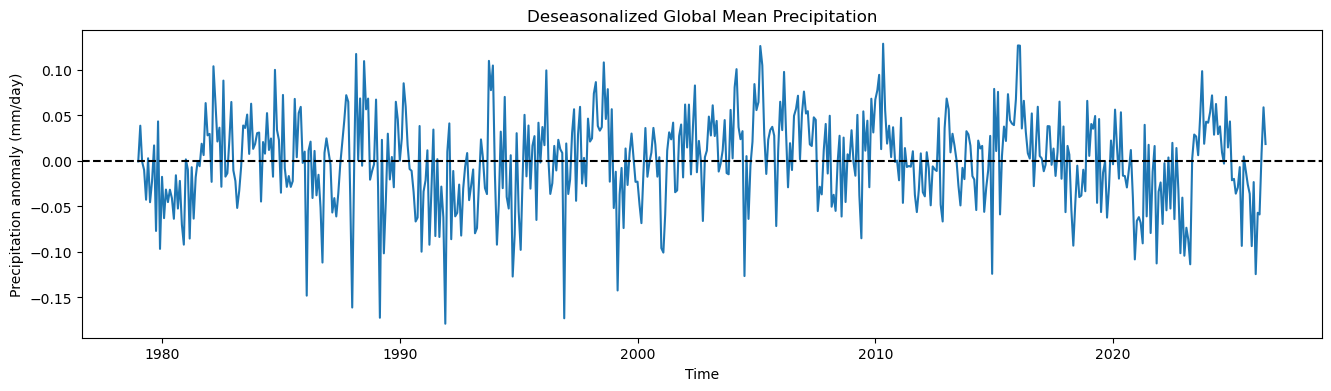

In [13]:
# 读取全部降水数据，跳过有问题的时间边界变量
rain = xr.open_dataset("precip.mon.mean.nc", drop_variables="time_bnds")["precip"]

# 计算全球月平均降水率
weights = np.cos(np.deg2rad(rain["lat"]))
rain_mean = rain.weighted(weights).mean(["lat", "lon"], skipna=True)

# 减去逐月气候态，去除平均季节周期
anomalies = rain_mean.groupby("time.month") - rain_mean.groupby("time.month").mean("time")

# 绘制时间序列
anomalies.plot(figsize=(16, 4))
plt.axhline(0, color="black", linestyle="--")
plt.title("Deseasonalized Global Mean Precipitation")
plt.ylabel("Precipitation anomaly (mm/day)")
plt.show()

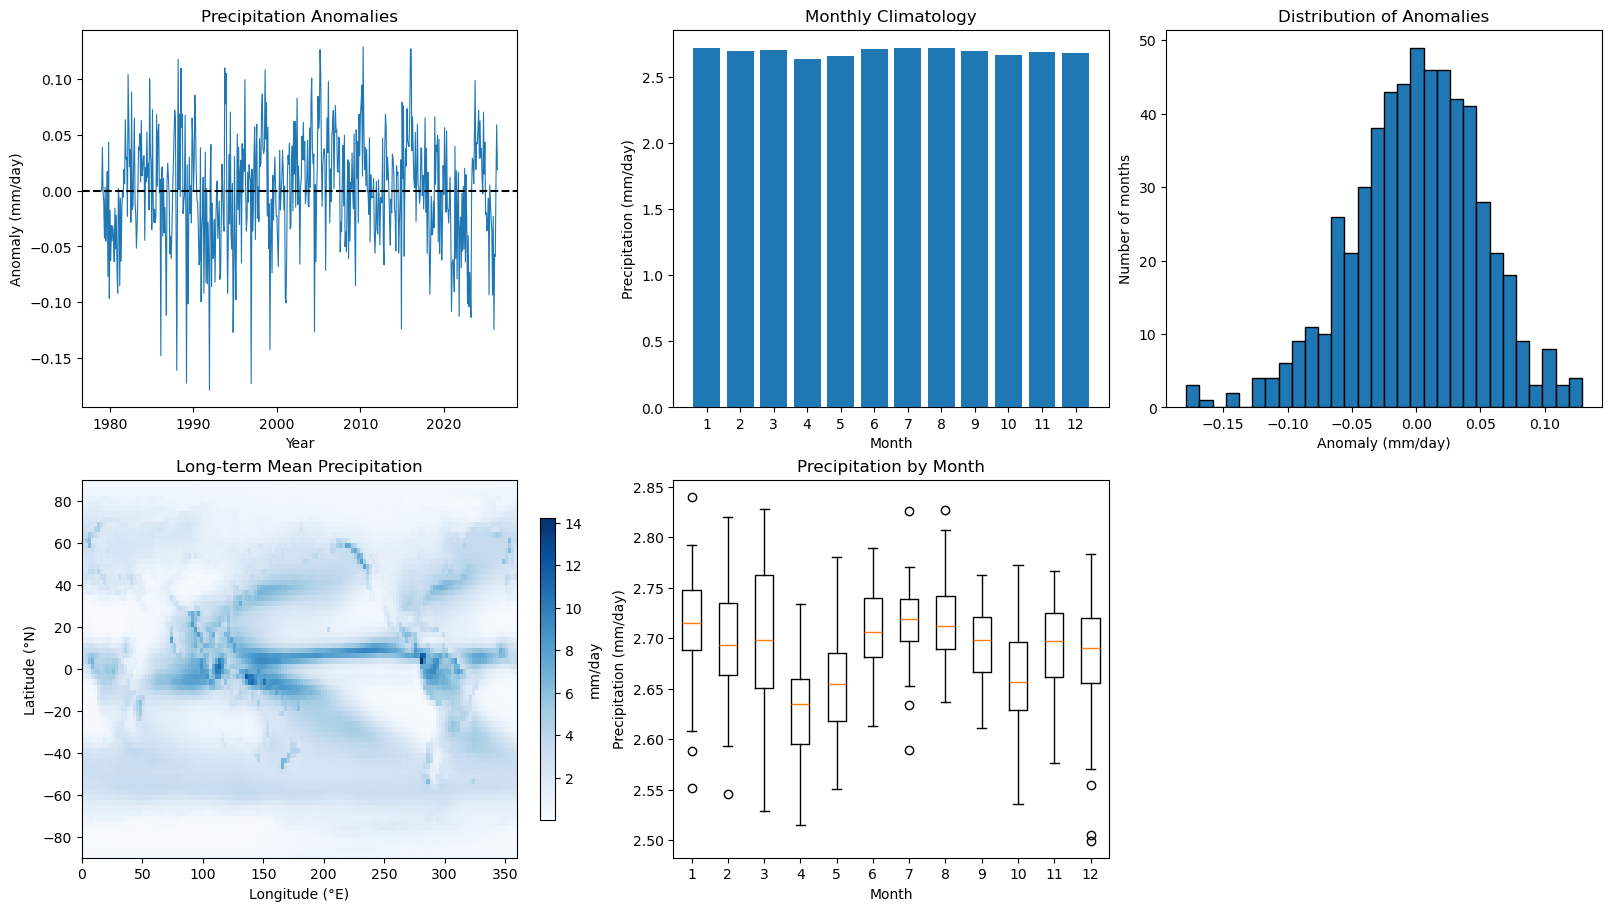

In [14]:
# 先创建2行3列的画板
fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
axes = axes.ravel()

# 1、去季节化降水率折线图
axes[0].plot(anomalies["time"], anomalies, linewidth=0.8)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set(title="Precipitation Anomalies",xlabel="Year", ylabel="Anomaly (mm/day)")

# 2、逐月气候态柱状图
climatology = rain_mean.groupby("time.month").mean("time")
axes[1].bar(climatology["month"], climatology)
axes[1].set_xticks(range(1, 13))
axes[1].set(title="Monthly Climatology",xlabel="Month", ylabel="Precipitation (mm/day)")

# 3、降水率异常直方图
axes[2].hist(anomalies.dropna("time").values, bins=30, edgecolor="black")
axes[2].set(title="Distribution of Anomalies",xlabel="Anomaly (mm/day)", ylabel="Number of months")

# 4、多年平均降水率空间分布图
rain.mean("time").plot(ax=axes[3], cmap="Blues",cbar_kwargs={"label": "mm/day", "shrink": 0.8})
axes[3].set(title="Long-term Mean Precipitation",xlabel="Longitude (°E)", ylabel="Latitude (°N)")

# 5、各月份降水率箱线图
groups = [values.dropna("time").values for month, values in rain_mean.groupby("time.month")]
axes[4].boxplot(groups)
axes[4].set(title="Precipitation by Month",xlabel="Month", ylabel="Precipitation (mm/day)")

# 隐藏多余的第6个子图
axes[5].axis("off")

plt.show()